# 自然语言处理

## 1 古典方法

本章先介绍古典方法，即深度学习出现以前的方法。

### 1.1 同义词词典

在同义词词典（thesaurus）中，具有相同含义的单词（同义词）或含义类似的单词（近义词）被归类到同一个组中。另外，在自然语言处理中用到的同义词词典有时会定义单词之间的粒度更细的关系，比如“上位-下位”关系、“整体-部分”关系。

在自然语言处理领域，最著名的同义词词典是普林斯顿大学于1985年开始开发的WordNet。使用WordNet，可以获得单词的近义词，或者利用单词网络计算单词之间的相似度。

同义词词典也存在一些较大的缺陷：

1. 难以顺应时代的变化：新词、新含义不断出现。
2. 人力成本高。
3. 无法表示近义词之间的细微差别。

为了避免这些问题，接下来我们将介绍基于计数的方法和利用神经网络的基于推理的方法。这两种方法可以从海量的文本数据中自动提取单词含义，将我们从人工关联单词的辛苦劳动中解放出来。

### 1.2 基于计数的方法

首先需要对语料库进行预处理，这里的预处理是将文本分割为单词，并将分割后的单词列表转化为单词ID列表。corpus是单词ID列表，word_to_id是单词到单词ID的字典，id_to_word是单词ID到单词的字典。

In [2]:
import numpy as np

def preprocess(text) -> tuple[np.ndarray, dict, dict]:

    text = text.lower()
    text = text.replace('.', ' .')
    words = text.split(' ')
    word_to_id = {}
    id_to_word = {}
    for word in words:
        if word not in word_to_id:
            new_id = len(word_to_id)
            word_to_id[word] = new_id
            id_to_word[new_id] = word
    corpus = np.array([word_to_id[w] for w in words])

    return corpus, word_to_id, id_to_word

text = 'You say goodbye and I say hello.'
corpus, word_to_id, id_to_word = preprocess(text)
print(corpus, word_to_id, id_to_word)

[0 1 2 3 4 1 5 6] {'you': 0, 'say': 1, 'goodbye': 2, 'and': 3, 'i': 4, 'hello': 5, '.': 6} {0: 'you', 1: 'say', 2: 'goodbye', 3: 'and', 4: 'i', 5: 'hello', 6: '.'}


分布式假设：某个单词的含义由它周围的单词形成。单词的分布式表示将单词表示为固定长度的向量，最直截了当的实现方法是对周围单词的数量进行计数。这里，我们将上下文的大小（周围单词的数量）称为窗口大小（window size）。简单起见，这里仅处理不考虑句子分隔符、左右单词数量相同的上下文。窗口大小为1，上下文包含左右各1个单词；窗口大小为2，上下文包含左右各2个单词，以此类推。

以上面的句子为例，我们将窗口大小设为1，从id为0的单词you开始计数。you的上下文仅有say这个单词，say的id为1，因此可以用向量[0, 1, 0, 0, 0, 0, 0]表示单词you。接下来看id为1的say，第一个say的上下文是you和goodbye，第二个say的上下文是i和hello，因此，可以用向量[1, 0, 1, 0, 1, 1, 0]来表示单词say。以此类推，可以得到七个向量，将其组合在一起，便可得到一个矩阵，称为共现矩阵（co-occurence matrix）。

In [3]:
def create_co_matrix(corpus, window_size = 1):

    vocab_size = np.unique(corpus).size
    co_matrix = np.zeros((vocab_size, vocab_size)) 
    for index, token_id in enumerate(corpus):
        for i in range(1, window_size + 1):
            if index >= i:
                co_matrix[token_id][corpus[index - i]] += 1
            if index <= len(corpus) - i - 1:
                co_matrix[token_id][corpus[index + i]] += 1

    return co_matrix

matrix = create_co_matrix(corpus)
print(matrix)

[[0. 1. 0. 0. 0. 0. 0.]
 [1. 0. 1. 0. 1. 1. 0.]
 [0. 1. 0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 1. 0. 0.]
 [0. 1. 0. 1. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 1. 0.]]


向量间的相似度可以用向量内积、欧氏距离等方法测量。在词向量的相似度方面，余弦相似度较为常用。设有$\bm{x}=(x_1,x_2,\cdots,x_n)$和$\bm{y}=(y_1,y_2,\cdots,y_n)$两个向量，它们之间的余弦相似度定义为
$$\cos(\theta)=\frac{\bm{x}\cdot\bm{y}}{\lVert A\rVert\lVert B\rVert}$$
余弦相似度直观地表示了“两个向量在多大程度上指向同一方向”。两个向量完全指向相同的方向时，余弦相似度为1；完全指向相反的方向时，余弦相似度为−1。

实现的时候，会给向量模长加上一个微小值$\varepsilon$以防止除0错误。

In [4]:
def cos_similarity(x, y, epsilon = 1e-8):

    f = lambda z: np.linalg.norm(z) + epsilon
    
    return np.dot(x, y) / (f(x) * f(y))

v1 = matrix[word_to_id['you']]
v2 = matrix[word_to_id['i']]
print(cos_similarity(v1, v2))

0.7071067691154799


使用cos_similarity函数时，我们可以实现另一个便利的函数：当某个单词被作为查询词时，将与这个查询词相似的单词按降序显示出来。

In [5]:
def most_similar(query, word_to_id, id_to_word, word_matrix, top=5):

    vocab_size = len(word_matrix)
    query_id = word_to_id[query]
    similarities = np.zeros(vocab_size)
    for i in range(vocab_size):
        if i != query_id:
            similarities[i] = cos_similarity(word_matrix[query_id], word_matrix[i])
    top_indices = np.argsort(similarities, descending=True)
    for index in top_indices[:top]:
        print(id_to_word[index], similarities[index])

most_similar("you", word_to_id, id_to_word, matrix)

goodbye 0.7071067691154799
i 0.7071067691154799
hello 0.7071067691154799
you 0.0
say 0.0


### 1.3 基于计数的方法的改进

上一节的共现矩阵的元素表示两个单词同时出现的次数。但是，这种“原始”的次数并不具备好的性质。如果我们看一下高频词，就能明白其原因了。比如，考虑某个语料库中the和car共现的情况。在这种情况下，它们的共现次数将会很大。我们已知car和drive也有很强的相关性。但是，如果只看单词的出现次数，那么与drive相比，the和car的相关性更强。这意味着，仅仅因
为the是个常用词，它就被认为与car有很强的相关性。

为了解决这一问题，可以使用点互信息（Pointwise Mutual Information，PMI）这一指标。对于随机变量x和y，它们的PMI定义为
$$
\mathrm{PMI}(x,y)=\log_2\frac{\Pr{(x,y)}}{\Pr{(x)}\Pr{(y)}}
$$
在具体实现中，为了从共现矩阵求PMI，将$\Pr{(x)}$定义为单词$x$与所有单词共现的概率、$\Pr{(x,y)}$定义为单词$x$和$y$共现的概率。设共现矩阵为$\bm{C}$，$x$和$y$的共现次数为$\bm{C}(x,y)$，单词$x$和$y$与所有单词的共现次数分别为$\bm{C}(x)$、$\bm{C}(y)$，所有单词与所有单词的共现次数（共现矩阵的元素之和）为$N$，则有
$$
\hat{\mathrm{PMI}}(x,y)=\log_2\frac{\frac{\bm{C}(x,y)}{N}}{\frac{\bm{C}(x)}{N}\frac{\bm{C}(y)}{N}}=\log_2 \frac{N\cdot \bm{C}(x,y)}{\bm{C}(x)\bm{C}(y)}
$$
下面我们来具体地算一下。假设N为10000，C(the)=100，C(car)=20，C(drive)=10，C(the,car)=10，C(car,drive)=5。如果从共现次数的角度来看，则与drive相比，the和car的相关性更强。而如果从PMI的角度来看，PMI("the","car")≈2.32，PMI("car","drive")≈7.97，与the相比，drive和car具有更强的相关性。这是因为为the本身出现得多，所以PMI的得分被拉低了。

虽然我们已经获得了PMI这样一个好的指标，但是PMI也有一个问题。那就是当两个单词的共现次数为0时，$log_2 0=−\infty$。为了解决这个问题，实践上我们会使用下述正的点互信息（Positive PMI，PPMI）：
$$
\mathrm{PPMI}(x,y)=\max(0,\mathrm{PMI}(x,y))
$$

In [6]:
def ppmi(c, epsilon = 1e-8):
    
    c_1 = np.zeros_like(c)
    n = np.sum(c)
    c_i = np.sum(c, axis=0)
    for i in range(np.size(c, axis=0)):
        for j in range(np.size(c, axis=1)):
            c_1[i][j] = max(0, np.log2(n * c[i][j] / (c_i[i] * c_i[j]) + epsilon))
    
    return c_1

matrix_ppmi = ppmi(matrix)
print(np.around(matrix_ppmi, 3))

[[0.    1.807 0.    0.    0.    0.    0.   ]
 [1.807 0.    0.807 0.    0.807 0.807 0.   ]
 [0.    0.807 0.    1.807 0.    0.    0.   ]
 [0.    0.    1.807 0.    1.807 0.    0.   ]
 [0.    0.807 0.    1.807 0.    0.    0.   ]
 [0.    0.807 0.    0.    0.    0.    2.807]
 [0.    0.    0.    0.    0.    2.807 0.   ]]


但是，这个PPMI矩阵还是存在一个很大的问题，那就是随着语料库的词汇量增加，各个单词向量的维数也会增加。另外，这个矩阵的很多元素都是0，这样的矩阵称为稀疏矩阵（sparse matrix）。这表明向量中的绝大多数元素并不重要。另外，这样的矩阵也容易受到噪声影响，稳健性差。对于这些问题，一个常见的方法是降维。降维（dimensionality reduction）就是从稀疏矩阵中找出重要的轴，用更少的维度对其进行重新表示。这样，稀疏矩阵就会被转化为大多数元素均不为0的密集矩阵。

降维的方法有很多，这里我们使用奇异值分解（Singular Value Decomposition，SVD）。SVD将任意m×n矩阵分解为3个矩阵的乘积，即
$$
\bm{X}=\bm{USV^\top}
$$
其中$\bm{U}_{m\times m}$和$\bm{V}_{n\times n}$是列向量彼此正交的正交矩阵，$\bm{U}$的列向量为$\bm{A}$的左奇异向量，对应$\bm{AA^\top}$的特征向量；$\bm{V}$的列向量为$\bm{A}$的右奇异向量，对应$\bm{A^\top A}$的特征向量，$\bm{S}_{m\times n}$是对角线上的元素为从大到小排列的奇异值、其他元素均为零的对角矩阵。

矩阵S中的奇异值越小，对应U中列向量的重要性越低。因此，可以通过去除矩阵U中列数较大的列向量来近似原始矩阵。若$\bm{X}$是共现矩阵，则可通过取$\bm{U}$的前$k$列来实现降维。

[[ 3.40948752e-01  5.55111512e-16]
 [-1.11022302e-16 -5.97636386e-01]
 [ 4.36312209e-01  8.32667268e-17]
 [-6.66133815e-16 -4.97828132e-01]
 [ 4.36312209e-01  1.01521897e-16]
 [ 7.09237099e-01  1.01521897e-16]
 [ 1.05471187e-15 -6.28488585e-01]]


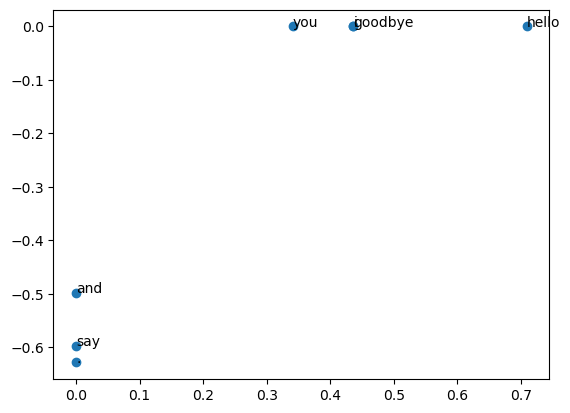

In [7]:
import matplotlib.pyplot as plt

u, s, v = np.linalg.svd(matrix_ppmi)
matrix_dr = u[:, :2]
print(matrix_dr)

for word, word_id in word_to_id.items():
    plt.annotate(word, (u[word_id, 0], u[word_id, 1]))
plt.scatter(u[:,0], u[:,1])
plt.show()

#### 1.3.4 PTB数据集

Penn Treebank（PTB）数据集是自然语言处理领域中广泛使用的语料库之一。它主要包含1989年《华尔街日报》的文章，总计约1百万个单词。

这里使用的数据进行了一些预处理，包括将稀有单词替换成特殊字符`<unk>`，将具体的数字替换成`N`等。此外，我们将所有句子连接起来，在每个句子的结尾处插入一个特殊字符`<eos>`，并将其视为一个大的时序数据。

In [8]:
def process(path):

    with open(path, 'r', encoding='utf-8') as f:
        data = f.read()
    text = data.replace('\n', '<eos>')
    words = text.split(' ')
    word_to_id = {}
    id_to_word = {}
    for word in words:
        if word not in word_to_id:
            new_id = len(word_to_id)
            word_to_id[word] = new_id
            id_to_word[new_id] = word
    corpus = np.array([word_to_id[w] for w in words])

    return corpus, word_to_id, id_to_word
'''
path = r'..\assets\files\ptb.train.txt'
corpus, word_to_id, id_to_word = process(path)
window_size = 2
wordvec_size = 100
matrix_1 = create_co_matrix(corpus, window_size)
matrix_2 = ppmi(matrix_1)
matrix_3, _, _ = np.linalg.svd(matrix_2)
matrix_4 = matrix_3[:, :wordvec_size]
querys = ['you', 'year', 'car', 'toyota']
for query in querys:
    print(f'[query] {query} ')
    most_similar(query, word_to_id, id_to_word, matrix_4, top=5)
'''

<>:18: SyntaxWarning: invalid escape sequence '\p'
<>:18: SyntaxWarning: invalid escape sequence '\p'
C:\Users\31653\AppData\Local\Temp\ipykernel_17472\2445089410.py:18: SyntaxWarning: invalid escape sequence '\p'
  path = r'..\assets\files\ptb.train.txt'


"\npath = r'..\x07ssets\x0ciles\\ptb.train.txt'\ncorpus, word_to_id, id_to_word = process(path)\nwindow_size = 2\nwordvec_size = 100\nmatrix_1 = create_co_matrix(corpus, window_size)\nmatrix_2 = ppmi(matrix_1)\nmatrix_3, _, _ = np.linalg.svd(matrix_2)\nmatrix_4 = matrix_3[:, :wordvec_size]\nquerys = ['you', 'year', 'car', 'toyota']\nfor query in querys:\n    print(f'[query] {query} ')\n    most_similar(query, word_to_id, id_to_word, matrix_4, top=5)\n"

观察结果可知，对于查询词you，可以看到i、we等人称代词排在前面，这些都是在语法上具有相同用法的词。再者，查询词year有month、quarter等近义词，查询词car有auto、vehicle等近义词。此外，将toyota作为查询词时，出现了nissan、honda和lexus等汽车制造商名或者品牌名。像这样，在含义或语法上相似的单词表示为相近的向量，这符合我们的直觉。

使用语料库，计算上下文中的单词数量，将它们转化PPMI矩阵，再基于SVD降维获得好的单词向量。这就是单词的分布式表示，每个单词表示为固定长度的密集向量。

## 2 word2vec

### 2.1 基于推理的方法

基于推理的方法的主要操作是推理，即给出某个位置周围的单词时，预测这个位置处会出现什么单词。基于推理的方法引入了神经网络，它接收上下文信息作为输入，并输出可能出现的各个单词的出现概率。作为模型学习的产物，我们得到了单词的分布式表示。由此可见，不管是哪种方法，如何对基于分布式假设的“单词共现”建模都是最重要的研究主题。

#### 2.1.1 单词的独热表示

要用神经网络处理单词，需要先将单词转化为固定长度的向量。对此，一种方式是将单词转换为独热向量（one-hot vector）。在独热表示中，只有一个元素是1，其他元素都是0。要将单词转化为独热表示，就需要准备元素个数与词汇个数相等的向量，并将单词ID对应的元素设为1，其他元素设为0。像这样，只要将单词转化为固定长度的向量，神经网络的输入层的神经元个数就可以固定下来。为了配合后文对word2vec的说明，本章使用的全连接层将省略偏置。

### 2.2 简单的word2vec

CBOW模型和skip-gram模型是word2vec中使用的两个神经网络模型。本节我们将主要讨论CBOW模型。

#### 2.2.1 CBOW模型

CBOW（Continuous Bag of Words）模型是根据上下文预测目标词的神经网络模型。CBOW模型的输入是['you', 'goodbye']这样的单词列表。我们将其转换为one-hot表示，以便模型可以进行处理。CBOW模型有两个输入层，经过中间层到达输出层。从输入层到中间层的变换由相同的全连接层（权重为$\bm{W}_{in}$）完成，从中间层到输出层神经元的变换由另一个全连接层（权重为$\bm{W}_{out}$）完成。这里，因为我们对上下文仅考虑两个单词，所以输入层有两个。如果对上下文考虑N个单词，则输入层会有N个。

中间层的神经元是各个输入层经全连接层变换后得到的值的平均。若经全连接层变换后，第1个输入层转化为$\bm{h}_1$，第2个输入层转化为$\bm{h}_2$，那么中间层的神经元是$\frac{1}{2}(\bm{h}_1+\bm{h}_2)$。中间层的神经元数量要比输入层少，因为中间层需要将预测单词所需的信息压缩保存，从而产生密集的向量表示。这时，中间层被写入了我们人类无法解读的数据，这相当于“编码”工作。而从中间层的信息获得期望结果的过程则称为“解码”。这一过程将被编码的信息复原为我们可以理解的形式。

输出层的神经元个数等于单个输入层的神经元个数。输出层的神经元是各个单词的得分，它的值越大，说明对应单词的出现概率就越高。得分是指在被解释为概率之前的值，对这些得分应用Softmax函数，就可以得到概率。

下面我们来实现CBOW模型的推理。

In [9]:
import numpy as np

# 'You say goodbye and I say hello.'
c_0 = np.array([[1, 0, 0, 0, 0, 0, 0]]) # 'you'
c_1 = np.array([[0, 0, 1, 0, 0, 0, 0]]) # 'goodbye'
w_in = np.random.randn(7, 3)
w_out = np.random.randn(3, 7)

class Affine:

    def __init__(self, w: np.ndarray, b: np.ndarray | None = None):

        if b is None:
            b = np.zeros(w.shape[-1], dtype=w.dtype)
        self.params = [w, b]
        self.grads = [np.zeros_like(w), np.zeros_like(b)]

    def forward(self, x:np.ndarray) -> np.ndarray:

        w, b = self.params
        self.x = x

        return np.dot(x, w) + b

    def backward(self, grad:np.ndarray) -> np.ndarray:

        w = self.params[0]
        self.grads[0][...] = np.dot(self.x.T, grad) # [...]取整个数组进行赋值，self.grads['w'] = ...只是更改绑定，没有修改原数组。
        self.grads[1][...] = np.sum(grad, axis=0) # 偏置在正向传播时进行了广播，反向传播时需要将梯度沿第零轴求和

        return np.dot(grad, w.T)

input_layer_1 = Affine(w_in)
input_layer_2 = Affine(w_in)
output_layer = Affine(w_out)
h_1 = input_layer_1.forward(c_0)
h_2 = input_layer_2.forward(c_1)
h = (h_1 + h_2) / 2
score = output_layer.forward(h)
print(score)

[[ 0.58157519 -1.76288885  1.57011781 -2.11930041 -0.19763906 -0.5095026
  -1.26470811]]


#### 2.2.2 word2vec的权重

如前所述，word2vec中使用的网络有两个权重，分别是输入侧的全连接层的权重（W_in）和输出侧的全连接层的权重（W_out）。那么，我们最终应该使用哪个权重作为单词的分布式表示呢？这里有三个选项：

1. 只使用输入侧的权重
2. 只使用输出侧的权重
3. 同时使用两个权重

在采用方案C的情况下，根据如何组合这两个权重，存在多种方式，其中一个方式就是简单地将这两个权重相加。

就word2vec（特别是skip-gram模型）而言，最受欢迎的是方案A。许多研究中也都仅使用输入侧的权重W_in作为最终的单词的分布式表示。遵循这一思路，我们也使用W_in作为单词的分布式表示。

#### 2.2.3 学习数据的准备

首先需要从语料库中生成上下文和目标词。我们需要用到之前实现的preprocess函数，从单词ID列表corpus生成contexts和target。contexts的各行为神经网络的输入，target的各行为正确解标签，均为独热向量。

In [10]:
import numpy as np

text = 'You say goodbye and I say hello.'
corpus, _, _ = preprocess(text)
def create_contexts_target(corpus, window_size=1):

    target = []
    contexts = []
    for index in range(window_size, len(corpus) - window_size):
        target.append(corpus[index])
        contexts.append(np.concatenate((corpus[index - window_size: index], corpus[index + 1: index + window_size + 1])))

    return np.array(contexts), np.array(target)
    
contexts, target = create_contexts_target(corpus)
vocab_size = len(np.unique(corpus))
contexts = np.eye(vocab_size)[contexts] # np.eye()生成单位阵
target = np.eye(vocab_size)[target]
print(contexts, target, sep='\n')

[[[1. 0. 0. 0. 0. 0. 0.]
  [0. 0. 1. 0. 0. 0. 0.]]

 [[0. 1. 0. 0. 0. 0. 0.]
  [0. 0. 0. 1. 0. 0. 0.]]

 [[0. 0. 1. 0. 0. 0. 0.]
  [0. 0. 0. 0. 1. 0. 0.]]

 [[0. 0. 0. 1. 0. 0. 0.]
  [0. 1. 0. 0. 0. 0. 0.]]

 [[0. 0. 0. 0. 1. 0. 0.]
  [0. 0. 0. 0. 0. 1. 0.]]

 [[0. 1. 0. 0. 0. 0. 0.]
  [0. 0. 0. 0. 0. 0. 1.]]]
[[0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0.]]


#### 2.2.4 CBOW模型的学习

现在，我们来考虑一下CBOW模型的学习。我们需要使用Softmax函数将得分转化为概率，再求这些概率和监督标签之间的交叉熵误差，并将其作为损失进行学习。此外，我们可以将Softmax层和Cross Entropy Error层实现为一个Softmax with Loss层。

softmax函数的表达式为
$$\mathrm{Softmax}(x)=\frac{e^{f(x)}}{\sum e^{f(x)}}$$
，其中$f(x)=x-\mathrm{Max}(x)$的实现为`f = x - np.max(x, axis=-1, keepdims=True)`

交叉熵损失函数的表达式为
$$\mathrm{Loss}(x,t)=-\sum t\log_e \mathrm{Softmax}(x)$$
，因此上式只计算对应正确解的输出的负自然对数。最后除以`x.shape[0]`便可得到平均交叉熵损失。

两式合并得
$$\mathrm{Loss}(x,t)=-\sum t\log_e(\frac{e^{f(x)}}{\sum e^{f(x)}})=-\sum t(f(x)-\log_e \sum e^{f(x)})=-\sum t\cdot g(x)$$

反向传播时将上游梯度乘以$\mathrm{Softmax}(x) - t$，再除以`x.shape[0]`即可。

In [11]:
class SoftmaxWithLoss:

    def forward(self, x, t):

        self.t = t
        f = x - np.max(x, axis=-1, keepdims=True)
        exp = np.exp(f)
        exp_sum = np.sum(exp, axis=-1, keepdims=True)
        self.y = exp / exp_sum
        g = f - np.log(exp_sum)

        return -np.sum(t * g) / x.shape[0]

    def backward(self, dout=1):

        return dout * (self.y - self.t) / self.y.shape[0]

class SimpleCBOW:

    def __init__(self, vocab_size, hidden_size):

        w_in = 0.01 * np.random.randn(vocab_size, hidden_size).astype(np.float32)
        w_out = 0.01 * np.random.randn(hidden_size, vocab_size).astype(np.float32)
        
        self.input_layer_0 = Affine(w_in)
        self.input_layer_1 = Affine(w_in)
        self.output_layer = Affine(w_out)
        self.loss_layer = SoftmaxWithLoss()
        self.word_vecs = w_in

        self.params, self.grads = [], []
        for layer in [self.input_layer_0, self.input_layer_1, self.output_layer]:
            self.params += layer.params
            self.grads += layer.grads

    def forward(self, contexts, target):
        
        h_0 = self.input_layer_0.forward(contexts[:, 0])
        h_1 = self.input_layer_1.forward(contexts[:, 1])
        score = self.output_layer.forward((h_0 + h_1) / 2)
        loss = self.loss_layer.forward(score, target)

        return loss

    def backward(self, grad_0=1):

        grad_1 = self.loss_layer.backward(grad_0)
        grad_2 = self.output_layer.backward(grad_1)
        self.input_layer_0.backward(0.5 * grad_2)
        self.input_layer_1.backward(0.5 * grad_2)

我们这里使用Adam算法进行参数更新。对于时间步$t$，给定梯度$g_t$，Adam的更新步骤如下：

1. 更新一阶矩：$m_t=\beta_1 m_{t-1}+(1-\beta_1)g_t$
2. 更新二阶矩：$v_t=\beta_2 v_{t-1}+(1-\beta_2)g_t^2$
3. 偏差修正：$\hat{m_t}=\frac{m_t}{1-\beta_1^t},\hat{v_t}=\frac{v_t}{1-\beta_2^t}$
4. 参数更新：$\theta_{t}=\theta_{t-1}-\eta\frac{\hat{m_t}}{\sqrt{\hat{v_t}}+\epsilon}$

其中$g_t^2$为$g_t$的逐元素平方。由于$m$和$v$的初始值为0，所以早期估计严重偏小，需要进行偏差修正。常用默认超参数为$\eta=0.001$、$\beta_1=0.9$、$\beta_2=0.999$、$\epsilon$=1e−8。

In [12]:
class Adam:

    def __init__(self, lr=0.001, beta_1=0.9, beta_2=0.999):
        
        self.lr = lr
        self.beta_1 = beta_1
        self.beta_2 = beta_2
        self.t = 0

    def update(self, params, grads):

        if self.t == 0:
            self.m = [np.zeros_like(p, dtype=np.float32) for p in params]
            self.v = [np.zeros_like(p, dtype=np.float32) for p in params]
        
        self.t += 1
        denom_1 = 1 - self.beta_1 ** self.t
        denom_2 = 1 - self.beta_2 ** self.t
        
        for i in range(len(params)):
            self.m[i] = self.beta_1 * self.m[i] + (1 - self.beta_1) * grads[i]
            self.v[i] = self.beta_2 * self.v[i] + (1 - self.beta_2) * np.square(grads[i])
            m_hat = self.m[i] / denom_1
            v_hat = self.v[i] / denom_2
            params[i] -= self.lr * m_hat / (np.sqrt(v_hat) + 1e-8)

在SimpleBOW中多个层共享相同的权重，因而params列表中存在多个相同的权重。在这种情况下，Adam、Momentum等优化器的运行会变得不符合预期。为此，Trainer类在更新参数时会进行简单的去重操作。

In [13]:
def remove_duplicate(params, grads):
    '''
    将参数列表中重复的权重整合为1个，
    加上与该权重对应的梯度
    '''
    params, grads = params[:], grads[:]  # copy list

    while True:
        find_flg = False
        L = len(params)

        for i in range(0, L - 1):
            for j in range(i + 1, L):
                # 在共享权重的情况下
                if params[i] is params[j]:
                    grads[i] += grads[j]  # 加上梯度
                    find_flg = True
                    params.pop(j)
                    grads.pop(j)
                # 在作为转置矩阵共享权重的情况下（weight tying）
                elif params[i].ndim == 2 and params[j].ndim == 2 and \
                     params[i].T.shape == params[j].shape and np.all(params[i].T == params[j]):
                    grads[i] += grads[j].T
                    find_flg = True
                    params.pop(j)
                    grads.pop(j)

                if find_flg: break
            if find_flg: break

        if not find_flg: break

    return params, grads

梯度裁剪是一种在反向传播后、参数更新前限制梯度大小的技术，常用方式包括按范数裁剪（如设定max_norm=1.0）和按值裁剪（如限制梯度在[-c, c]区间），用于防止梯度爆炸导致参数更新过大、训练发散或出现NaN/Inf。

按范数裁剪首先计算所有参数梯度的整体L2范数，若大于max_norm，则按比例缩放梯度（乘以max_norm/整体范数），保持梯度方向不变。

大模型训练首选按范数裁剪，这里同样也使用按范数裁剪。

In [14]:
def clip_grads(grads, max_norm):
    total_norm = 0
    for grad in grads:
        total_norm += np.sum(grad ** 2)
    total_norm = np.sqrt(total_norm)

    rate = max_norm / (total_norm + 1e-6)
    if rate < 1:
        for grad in grads:
            grad *= rate

这里，我们使用Trainer类来执行学习过程。

In [15]:
import time

class Trainer:
    def __init__(self, model, optimizer):
        self.model = model
        self.optimizer = optimizer
        self.loss_list = []
        self.eval_interval = None
        self.current_epoch = 0

    def fit(self, x, t, max_epoch=10, batch_size=32, max_grad=None, eval_interval=20):
        data_size = len(x)
        max_iters = data_size // batch_size
        self.eval_interval = eval_interval
        model, optimizer = self.model, self.optimizer
        total_loss = 0
        loss_count = 0

        start_time = time.time()
        for epoch in range(max_epoch):
            # 打乱
            idx = np.random.permutation(np.arange(data_size))
            x = x[idx]
            t = t[idx]

            for iters in range(max_iters):
                batch_x = x[iters*batch_size:(iters+1)*batch_size]
                batch_t = t[iters*batch_size:(iters+1)*batch_size]

                # 计算梯度，更新参数
                loss = model.forward(batch_x, batch_t)
                model.backward()
                params, grads = remove_duplicate(model.params, model.grads)  # 将共享的权重整合为1个
                if max_grad is not None:
                    clip_grads(grads, max_grad)
                optimizer.update(params, grads)
                total_loss += loss
                loss_count += 1

                # 评价
                if (eval_interval is not None) and (iters % eval_interval) == 0:
                    avg_loss = total_loss / loss_count
                    elapsed_time = time.time() - start_time
                    print('| epoch %d |  iter %d / %d | time %d[s] | loss %.2f'
                          % (self.current_epoch + 1, iters + 1, max_iters, elapsed_time, avg_loss))
                    self.loss_list.append(float(avg_loss))
                    total_loss, loss_count = 0, 0

            self.current_epoch += 1

    def plot(self, ylim=None):
        x = np.arange(len(self.loss_list))
        if ylim is not None:
            plt.ylim(*ylim)
        plt.plot(x, self.loss_list, label='train')
        plt.xlabel('iterations (x' + str(self.eval_interval) + ')')
        plt.ylabel('loss')
        plt.show()

| epoch 1 |  iter 1 / 2 | time 0[s] | loss 1.95
| epoch 2 |  iter 1 / 2 | time 0[s] | loss 1.95
| epoch 3 |  iter 1 / 2 | time 0[s] | loss 1.94
| epoch 4 |  iter 1 / 2 | time 0[s] | loss 1.94
| epoch 5 |  iter 1 / 2 | time 0[s] | loss 1.94
| epoch 6 |  iter 1 / 2 | time 0[s] | loss 1.94
| epoch 7 |  iter 1 / 2 | time 0[s] | loss 1.94
| epoch 8 |  iter 1 / 2 | time 0[s] | loss 1.94
| epoch 9 |  iter 1 / 2 | time 0[s] | loss 1.94
| epoch 10 |  iter 1 / 2 | time 0[s] | loss 1.93
| epoch 11 |  iter 1 / 2 | time 0[s] | loss 1.94
| epoch 12 |  iter 1 / 2 | time 0[s] | loss 1.93
| epoch 13 |  iter 1 / 2 | time 0[s] | loss 1.93
| epoch 14 |  iter 1 / 2 | time 0[s] | loss 1.94
| epoch 15 |  iter 1 / 2 | time 0[s] | loss 1.93
| epoch 16 |  iter 1 / 2 | time 0[s] | loss 1.93
| epoch 17 |  iter 1 / 2 | time 0[s] | loss 1.93
| epoch 18 |  iter 1 / 2 | time 0[s] | loss 1.92
| epoch 19 |  iter 1 / 2 | time 0[s] | loss 1.93
| epoch 20 |  iter 1 / 2 | time 0[s] | loss 1.93
| epoch 21 |  iter 1 / 2 | ti

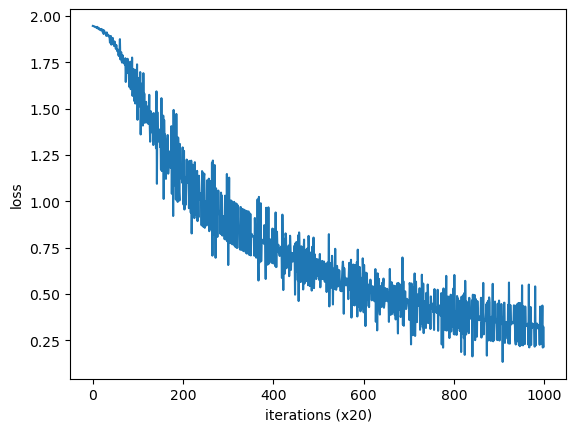

you [-0.5852683  -0.86168075  0.8741994  -1.7723242   0.85692847]
say [ 0.5241083   1.2568272  -1.2616265  -0.96712416 -1.2479024 ]
goodbye [-0.81981295 -0.92016405  0.8637689   1.0573133   0.92683285]
and [-2.1711102  1.1573169 -1.1874098 -0.4634875 -1.161377 ]
i [-0.80487573 -0.90554506  0.905876    1.0658453   0.9313643 ]
hello [-0.58330405 -0.8692753   0.88359463 -1.7576727   0.84716535]
. [ 1.6887606   0.9954415  -0.97165006 -1.2776653  -0.94371086]


In [16]:
window_size = 1
hidden_size = 5
batch_size = 3
max_epoch = 1000

text = 'You say goodbye and I say hello.'

corpus, word_to_id, id_to_word = preprocess(text)
vocab_size = len(word_to_id)
contexts, target = create_contexts_target(corpus, window_size)
contexts = np.eye(vocab_size, dtype=np.float32)[contexts]
target = np.eye(vocab_size, dtype=np.float32)[target]
model = SimpleCBOW(vocab_size, hidden_size)
optimizer = Adam()
trainer = Trainer(model, optimizer)
trainer.fit(contexts, target, max_epoch, batch_size)
trainer.plot()
word_vecs = model.word_vecs
for word_id, word in id_to_word.items():
    print(word, word_vecs[word_id])

#### 2.2.5 CBOW模型和概率

CBOW模型从给定的上下文来预测目标词，可以用后验概率建模为$$\Pr(w_t|w_{t-1},w_{t+1})$$
，即在$w_{t-1}$和$w_{t+1}$发生后，$w_t$发生的概率。
使用这个式子可以简洁地表示CBOW模型的损失函数。我们知道交叉熵损失函数实际上输出的是正确解概率的负自然对数，那么以上下文窗口大小为1为例，我们可以将CBOW模型的损失函数表示为
$$L=-\log\Pr(w_t|w_{t-1},w_{t+1})$$
，称为负对数似然（negative log likelihood）。

### 2.3 skip-gram模型

不同于CBOW模型，skip-gram模型从目标词预测上下文。因此，skip-gram模型的输入层只有一个，输出层的数量则为上下文的单词个数。以上下文窗口大小为1为例，可以用概率建模为
$$\Pr(w_{t-1},w_{t+1}|w_t)$$
在skip-gram模型中，假定上文和下文单词条件独立，则上式可进行分解：
$$\Pr(w_{t-1},w_{t+1}|w_t)=\Pr(w_{t-1}|w_t)\Pr(w_{t+1}|w_t)$$
将上式代入交叉熵损失函数，可得
$$L=-\log\Pr(w_{t-1}|w_t)\Pr(w_{t+1}|w_t)=-(\log\Pr(w_{t-1}|w_t)+\log\Pr(w_{t+1}|w_t))$$
因此在计算损失时，首先要分别求出各个输出层的损失，然后将它们加起来作为最后的损失。

Skip-gram模型的优缺点如下：
- 优点：Skip-gram模型在训练过程中，每个中心词都会从多个上下文词中学习信息，信息利用更加充分，能够更好地捕捉低频词的语义信息。
- 缺点：Skip-gram模型需要对每个中心词进行多次预测，复杂度为O(KV)，其中K是窗口大小，V是词汇表的大小，训练时间较长。

相应地，CBOW模型训练速度快，但信息利用不充分，对低频词效果差。

In [17]:
class SimpleSkipGram:

    def __init__(self, vocab_size, hidden_size):

        W_in = 0.01 * np.random.randn(vocab_size, hidden_size).astype('f')
        W_out = 0.01 * np.random.randn(hidden_size, vocab_size).astype('f')

        self.in_layer = Affine(W_in)
        self.out_layer = Affine(W_out)
        self.loss_layer1 = SoftmaxWithLoss()
        self.loss_layer2 = SoftmaxWithLoss()

        self.params, self.grads = [], []
        for layer in [self.in_layer, self.out_layer]:
            self.params += layer.params
            self.grads += layer.grads

        self.word_vecs = W_in

    def forward(self, contexts, target):

        h = self.in_layer.forward(target)
        s = self.out_layer.forward(h)
        l1 = self.loss_layer1.forward(s, contexts[:, 0])
        l2 = self.loss_layer2.forward(s, contexts[:, 1])

        return l1 + l2

    def backward(self, dout=1):

        dl1 = self.loss_layer1.backward(dout)
        dl2 = self.loss_layer2.backward(dout)
        ds = dl1 + dl2
        dh = self.out_layer.backward(ds)
        self.in_layer.backward(dh)

### 2.4 基于计数与基于推理

到目前为止，我们已经了解了基于计数的方法和基于推理的方法。两种方法在学习机制上存在显著差异：基于计数的方法通过对整个语料库的统计数据进行一次学习来获得单词的分布式表示，而基于推理的方法则反复观察语料库的一部分数据进行学习。这里，我们就其他方面来对比一下这两种方法。

首先，我们考虑需要向词汇表添加新词并更新单词的分布式表示的场景。此时，基于计数的方法需要从头开始计算。即便是想稍微修改一下单词的分布式表示，也需要重新完成生成共现矩阵、进行SVD等一系列操作。相反，基于推理的方法允许参数的增量学习。具体来说，可以将之前学习到的权重作为下一次学习的初始值，在不损失之前学习到的经验的情况下，高效地更新单词的分布式表示。在这方面，基于推理的方法具有优势。

其次，就分布式表示的性质而言，基于计数的方法主要是编码单词的相似性，而基于推理的方法除了单词的相似性以外，还能理解更复杂的单词之间的模式。关于这一点，word2vec因能解开“king − man + woman = queen”这样的类推问题而知名。

这里有一个常见的误解，那就是基于推理的方法在准确度方面优于基于计数的方法。实际上，有研究表明，就单词相似性的定量评价而言，基于推理的方法和基于计数的方法难分上下。

此外，在word2vec之后，有研究人员提出了GloVe方法。GloVe方法融合了基于推理的方法和基于计数的方法。该方法的思想是，将整个语料库的统计数据的信息纳入损失函数，进行学习。据此，这两个方法论成功地被融合在了一起。

## 3 word2vec的高速化

### 3.1 嵌入层

独热向量存在维度灾难、稀疏性严重、向量之间无关联等问题。独热向量与权重矩阵相乘，实际上就是将矩阵的特定行取出来。因此，我们可以将独热向量与矩阵乘法转换为切片操作，向量只需要保存索引，这样就实现了向低维稠密向量的转换，这样的单词密集向量表示称为词嵌入（word embedding）。

反向传播时不能直接根据索引赋值，如`self.grads[0][self.indices] = grad`，否则索引重复时值会覆盖。我们想要的效果是累加，`np.add.at`会根据索引将grad广播后加到self.grads[0]的对应行。

In [ ]:
class Embedding:

    def __init__(self, w):
        self.params = [w]
        self.grads = [np.zeros_like(w)]

    def forward(self, indices):
        self.indices = indices
        return self.params[0][indices]

    def backward(self, grad):
        self.grads[0][...] = 0 # 先清空梯度
        np.add.at(self.grads[0], self.indices, grad)

### 3.2 负采样

#### 3.2.1 从多分类到二分类

到目前为止，我们处理的都是多分类问题。拿刚才的例子来说，我们把它看作了从100万个单词中选择1个正确单词的任务。那么，可不可以用二分类问题来拟合这个多分类问题呢？

现在，我们来考虑如何将多分类问题转化为二分类问题。二分类处理的是答案为“Yes/No”的问题。比如，让神经网络来回答“当
上下文是you和goodbye时，目标词是say吗？”这个问题，这时输出层只需要一个神经元即可。可以认为输出层的神经元输出的是say的得分。因此，要计算中间层和输出侧的权重矩阵的乘积，只需要提取say对应的列向量，并用它与中间层的神经元计算内积即可。

在多分类的情况下，输出层使用Softmax函数将得分转化为概率，损失函数使用交叉熵误差。在二分类的情况下，输出层使用sigmoid函数，损失函数也使用交叉熵误差。

sigmoid函数的表达式为
$$y=\frac{1}{1+e^{-x}}$$
其图像呈S形，输入值x被转化为0到1之间的实数，因此sigmoid函数的输出y可以解释为概率。

用于sigmoid函数的损失函数也是交叉熵误差，其表达式为
$$L=-(t\log y+(1-t)\log(1-y))$$
其中$t$是正确解标签，取值为0或1。$t=1$时输出$-\log y$，$t=0$时输出$-\log(1-y)$。

设sigmoid函数的输出为$y$，则Sigmoid with Loss层反向传播时只需要给上游梯度乘以$y-t$。这意味着当正确解标
签是1时，如果y尽可能地接近1，误差将很小，模型学习得少；反之若y远离1，误差将增大，模型学习得多。

In [ ]:
class SigmoidWithLoss:
    def __init__(self):
        pass

    def forward(self, x, t):
        self.y = 1 / (1 + np.exp(-x))
        self.t = t
        return np.sum(-(t * np.log(self.y) + (1 - t) * np.log(1 - self.y)))

    def backward(self, dout=1):
        return dout * (self.y - self.t) / self.y.shape[0] # 平均交叉熵损失

注意对于批处理，并不是将W_out_embed与h直接做矩阵乘法，而是将它们的对应行向量相乘。实现中将两个矩阵逐元素相乘，再按照第二轴求和。

这里引入EmbeddingDot层，将Embedding层和dot运算合并。

求和的偏导数是广播，numpy数组进行乘法运算时会自动进行广播。但grad的形状是（batch_size,），self.h和self.w_embed的形状是（batch_size, hidden_dim），相乘时grad会被广播为（1, batch_size），出现维度不匹配（第二维）的错误。因此这里需要将grad的形状转换为（batch_size, 1）

In [ ]:
class EmbeddingDot:

    def __init__(self, w):
        self.params = [w]
        self.grads = [np.zeros_like(w)]

    def forward(self, h, indices):
        self.h = h
        self.indices = indices
        self.w_embed = self.params[0][indices]
        return np.sum(h * self.w_embed, axis=1)

    def backward(self, grad):
        grad = grad.reshape(grad.shape[0], 1)
        self.grads[0][...] = 0 # 清空梯度
        np.add.at(self.grads[0], self.indices, self.h * grad)
        return grad * self.w_embed

#### 3.2.2 负采样

当前的神经网络只是学习了正例，但是对正例之外的负例一无所知。而我们真正要做的事情是，对于正例，使Sigmoid层的输出接近1；对于负例（正例以外的单词），使Sigmoid层的输出接近0。

但是如果以所有的负例为对象，词汇量将暴增至无法处理。为此，作为一种近似方法，我们将选择若干个（5个或10个）负例进行学习，这就是负采样方法的含义。

总之，负采样方法将正例的损失与采样得到的负例的损失加起来，作为最终的损失。

下面我们来看一下如何抽取负例。关于这一点，基于语料库的统计数据进行采样的方法比随机抽样要好。具体来说，就是让语料库中经常出现的单词容易被抽到，让语料库中不经常出现的单词难以被抽到。基于语料库中单词使用频率的采样方法会先计算语料库中各个单词的出现次数，并将其表示为“概率分布”，然后使用这个概率分布对单词进行采样。

word2vec中提出的负采样对刚才的概率分布增加了一个步骤，即对原来的概率分布取0.75次方，用数学式表示为
$$\Pr^\prime(w_i)=\frac{\Pr(w_i)^{0.75}}{\sum_j^n\Pr(w_j)^{0.75}}=\frac{(\frac{n(w_i)}{N})^{0.75}}{(\sum_j^n\frac{n(w_j)}{N})^{0.75}}=\frac{n(w_i)^{0.75}}{\sum_j^n n(w_j)^{0.75}}$$
这是为了防止低频单词被忽略。更准确地说，通过取0.75次方，低频单词的概率将稍微变高。此外，0.75这个值并没有什么理论依据，也可以设置成0.75以外的值。实现时，一般会使用化简后的式子。

为了加速计算，实现时通常进行有放回抽样，且负采样时不排除目标词。目标词恰好被抽到，属于概率极低的“小噪声”，对最终词向量影响可以忽略

In [ ]:
from collections import Counter

class UnigramSampler:
    def __init__(self, corpus, power, sample_size):
        self.sample_size = sample_size
        counts = Counter(corpus)
        self.vocab_size = len(counts)
        self.probs = np.zeros(self.vocab_size)
        for i in range(self.vocab_size):
            self.probs[i] = counts[i]
        self.probs = np.power(self.probs, power)
        total = np.sum(self.probs)
        self.probs /= total

    def get_negative_sample(self, target):
        batch_size = target.shape[0]
        return np.random.choice(self.vocab_size, size=(batch_size, self.sample_size), replace=True, p=self.probs)

corpus = np.array([0, 1, 2, 3, 4, 1, 2, 3])
power = 0.75
sample_size = 2
sampler = UnigramSampler(corpus, power, sample_size)
target = np.array([1, 3, 0])
negative_sample = sampler.get_negative_sample(target)
print(negative_sample)

[[3 1]
 [3 0]
 [2 3]]


In [ ]:
class NegativeSamplingLoss:
    def __init__(self, w, corpus, power, sample_size):
        self.sample_size = sample_size
        self.sampler = UnigramSampler(corpus, power, sample_size)
        self.embed_dot_layers = [EmbeddingDot(w) for _ in range(sample_size + 1)]
        self.loss_layers = [SigmoidWithLoss() for _ in range(sample_size + 1)]
        self.params, self.grads = [], []
        for layer in self.embed_dot_layers:
            self.params += layer.params
            self.grads += layer.grads

    def forward(self, h, target):
        batch_size = target.shape[0]
        neg_targets = sampler.get_negative_sample(target)

        score = self.embed_dot_layers[0].forward(h, target)
        loss = self.loss_layers[0].forward(score, np.ones(batch_size))

        for i in range(sample_size - 1):
            score = self.embed_dot_layers[i+1].forward(h, neg_targets[:, i])
            loss += self.loss_layers[i+1].forward(score, np.zeros(batch_size))

        return loss

    def backward(self, dout=1):
        dh = 0
        for i in range(sample_size):
            dscore = self.loss_layers[i].backward(dout)
            dh += self.embed_dot_layers[i].backward(dscore)
        return dh

### 3.3 改进版word2vec的学习

这里，我们将改进上一节的SimpleCBOW类，来实现CBOW模型。改进之处在于使用Embedding层和Negative Sampling Loss层。此外，我们将上下文部分扩展为可以处理任意的窗口大小。